<a href="https://colab.research.google.com/github/saharmansourirad/EssentialGIN/blob/main/01_scRNA_seq_QC_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q "anndata==0.11.4" "scanpy==1.11.5" "pandas==2.2.3"
%pip install -q scanpy
%pip install -q "zarr<3"

In [ ]:
import pandas as pd
import scanpy as sc
from importlib.metadata import version

print("Pandas:", version("pandas"))
print("AnnData:", version("anndata"))
print("Scanpy:", version("scanpy"))

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 2 # print informational messages and progress

adata = sc.datasets.pbmc3k()

print(adata)
print("Cells:", adata.n_obs) # number of cells
print("Genes:", adata.n_vars) # number of genes

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
Cells: 2700
Genes: 32738


In [4]:
# Identify mitochondrial genes in human data
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate QC metrics for each cell
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    inplace=True
)

# Inspect the first few cells
adata.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
index,,,
AAACATACAACCAC-1,781,2421.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,1.743085
AAACCGTGTATGCG-1,522,981.0,1.223242


**n_genes_by_counts:** How many genes were detected in each cell.

**total_counts:** Total observed RNA counts for each cell.

**pct_counts_mt:** Measures what percentage of the cell's total counts come from mitochondrial genes.


These three metrics help you check the quality of each cell in your single-cell RNA-seq dataset.
The main difference is that n_genes_by_counts counts genes, while total_counts counts the observed RNA counts.


Suppose one cell has the following counts:
Gene	Observed counts
Gene A	5
Gene B	3
Gene C	0
Gene D	2
Gene E	0

**1. n_genes_by_counts = 3**
Counts how many genes have at least one observed count.
Genes A, B and D are detected, so there are 3 detected genes.


**2. total_counts = 10**
Adds up all the observed counts across the genes.
\(5+3+0+2+0=10\)


**3. pct_counts_mt = depends on mitochondrial counts**
Measures what percentage of the cell's total counts come from mitochondrial genes.
If 2 of the 10 counts are mitochondrial, the percentage is \(2/10\times100=20\%\).


Why do we need both n_genes_by_counts and total_counts?

Imagine two cells:

Metric	Cell A	Cell B

n_genes_by_counts	1,000	1,000

total_counts	2,000	10,000

Average counts per detected gene	2	10

Both cells have the same number of detected genes, but Cell B has five times as many observed counts.

This can happen because genes have different expression levels or because different numbers of RNA molecules were captured and sequenced.

- Low n_genes_by_counts: may indicate a low-quality cell, an empty droplet or a cell with little RNA.
- Low total_counts: may indicate low sequencing depth or low RNA content.
- High pct_counts_mt: may indicate a damaged or stressed cell, although normal values vary by cell type and tissue.

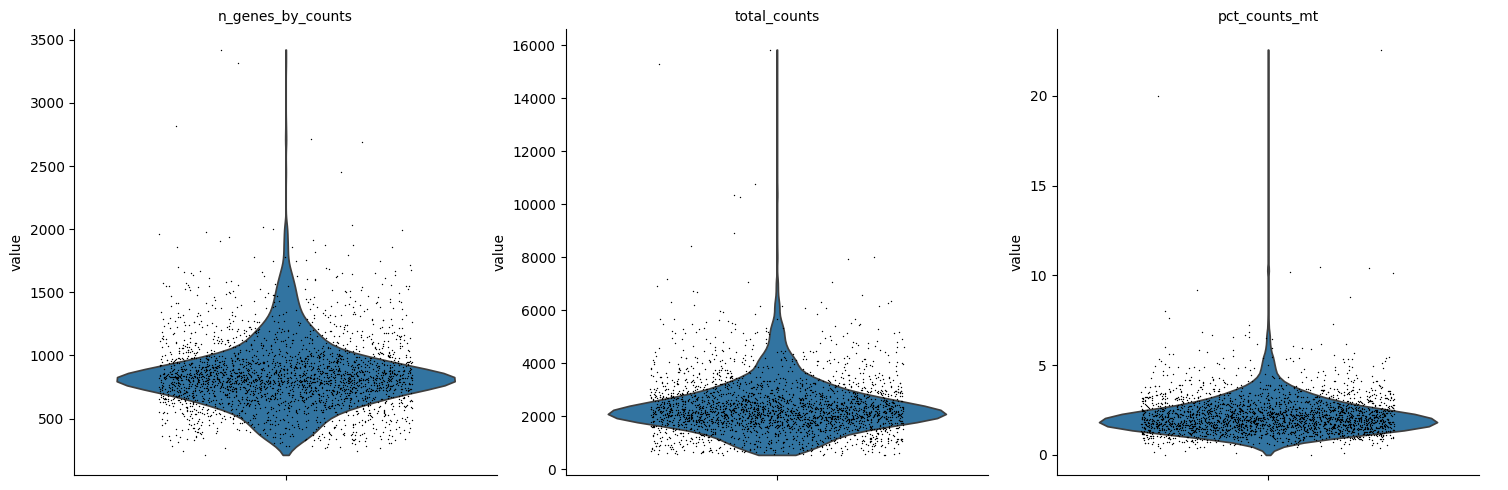

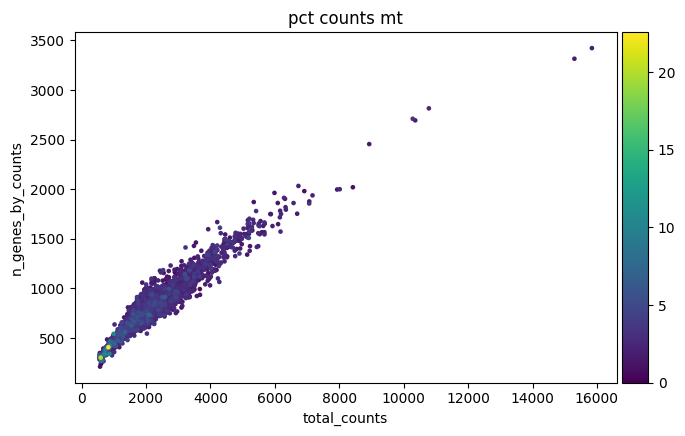

In [5]:
# Visualize cell quality
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.3,
    multi_panel=True
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

**Plots before filtering**

 Cells with very few detected genes may be low quality.

Cells with unusually high counts or gene numbers may be doublets.

 High mitochondrial percentages can indicate stressed or damaged cells, although this depends on the tissue and experiment.

In [6]:
#Filter cells and genes

print("Before filtering:", adata.shape)

# Remove cells with fewer than 200 detected genes
sc.pp.filter_cells(adata, min_genes=200)

# Remove genes detected in fewer than 3 cells
sc.pp.filter_genes(adata, min_cells=3)

# Apply a provisional mitochondrial threshold
adata = adata[adata.obs["pct_counts_mt"] < 15].copy()

print("After filtering:", adata.shape)

Before filtering: (2700, 32738)
filtered out 19024 genes that are detected in less than 3 cells
After filtering: (2698, 13714)


In [7]:
# Save raw counts and normalize

# Preserve the count matrix before transforming it
adata.layers["counts"] = adata.X.copy()

# Normalize each cell to a total of 10,000 counts
sc.pp.normalize_total(adata, target_sum=1e4)

# Apply log(1 + x) transformation
sc.pp.log1p(adata)

print(adata)

normalizing counts per cell
    finished (0:00:05)
AnnData object with n_obs × n_vars = 2698 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'log1p'
    layers: 'counts'


Why do we do this?
- **Normalization** reduces differences caused by cells having different total numbers of observed counts.
- **Log transformation** compresses the range of values so that very large counts have less influence.
We keep the original counts in adata.layers["counts"] because some later analyses need them.

extracting highly variable genes
    finished (0:00:00)
Highly variable genes: 2000


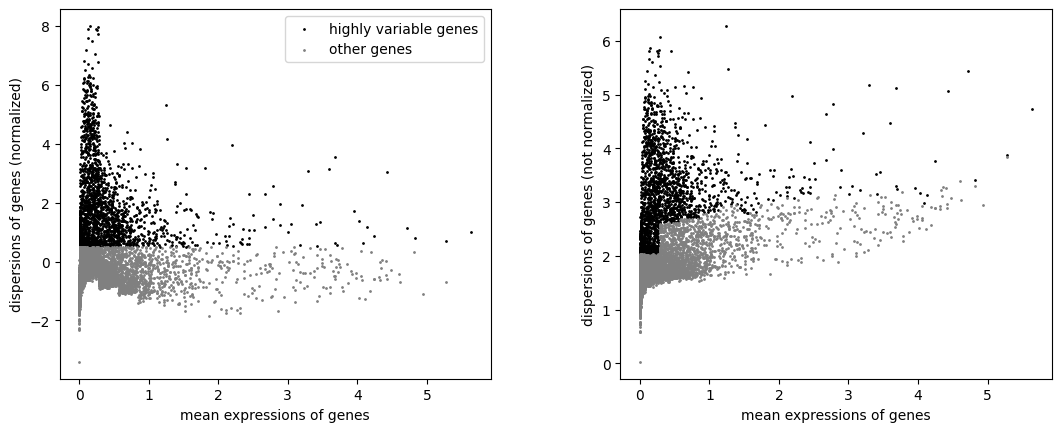

In [8]:
# Select highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print(
    "Highly variable genes:",
    adata.var["highly_variable"].sum()
)

sc.pl.highly_variable_genes(adata)

Highly variable genes show substantial variation across cells. They are often useful for discovering cell populations, though variation can also reflect technical effects.
We mark these genes rather than removing the other genes from the dataset.

In [10]:
adata.write_h5ad("pbmc3k_preprocessed.h5ad")

print("Saved processed dataset.")

Saved processed dataset.


The .h5ad file stores the **expression matrix**, **metadata** and **preprocessing** **results**.